In [2]:
from rdkit import Chem
import os
from rdkit.Chem.Draw import IPythonConsole
ptable = Chem.GetPeriodicTable()
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}


In [3]:
"""
Rule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks
Rule 2: Identify suitable leaving groups (suitable sigma star)
Rule 2.5: Identify reactive sigma bonds
Rule 3: Identify acidic hydrogens
"""

'\nRule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks\nRule 2: Identify suitable leaving groups (suitable sigma star)\nRule 2.5: Identify reactive sigma bonds\nRule 3: Identify acidic hydrogens\n'

In [4]:
def identify_source(mol, rules = "all"):
    for atom in mol.GetAtoms():
        # Look for hydrides - M-H bond
        if electronegativity_dict[atom.GetAtomicNum()] < 2.05 and atom.GetFormalCharge() < 0 and atom.GetNumExplicitHs() > 0:
            atom.SetProp('source', 'hydride')

        # Look for lone pairs
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        if lone_electrons > 0:
            atom.SetProp('source', 'lone pair')
            
    for bond in mol.GetBonds():
        atoms = [bond.GetBeginAtom(), bond.GetEndAtom()]
        # Conditional on rules being on
        if rules == 'all':
            if bond.GetBondTypeAsDouble() == 1:
                # This is an experimental feature - unlikely to be a very common reaction mode
                if electronegativity_dict[atoms[0].GetAtomicNum()] < 2.05 and electronegativity_dict[atoms[1].GetAtomicNum()] < 2.05:
                    bond.SetProp('source', 'sigma bond')
                    bond.SetProp('source_bond_atom', 'both')
                    bond.SetProp('source_other_atom', 'both')
                # For any element less electronegative than boron (inclusive) - add sigma bond as source - going from more electronegative atom
                for a in atoms:
                    if electronegativity_dict[a.GetAtomicNum()] < 2.05:
                        other = a.GetIdx()
                        source = bond.GetOtherAtomIdx(other)
                        # avoid breaking a sigma bond if the source atom instead has a lone pair
                        if mol.GetAtomWithIdx(source).HasProp('source') and mol.GetAtomWithIdx(source).GetProp('source') == 'lone pair':
                            continue
                        bond.SetProp('source', 'sigma bond')
                        bond.SetIntProp('source_bond_atom', source)
                        bond.SetIntProp('source_other_atom', other)

        # Looking for double and triple bonds - ignoring aromatic systems
        if bond.GetBondTypeAsDouble() > 1.5:
            
            atoms = [bond.GetBeginAtom() ,bond.GetEndAtom()]

            # if bond is homonuclear then either atom can be source
            if atoms[0].GetAtomicNum() == atoms[1].GetAtomicNum():
                bond.SetProp('source', 'pi bond')
                bond.SetProp('source_bond_atom', 'both')
                bond.SetProp('source_other_atom', 'both')
            else:
                if electronegativity_dict[atoms[0].GetAtomicNum()] < electronegativity_dict[atoms[1].GetAtomicNum()]:
                    # avoid breaking pi bond is the source atom has a lone pair
                    if atoms[1].HasProp('source') and atoms[1].GetProp('source') == 'lone pair':
                        continue
                    bond.SetProp('source', 'pi bond')
                    bond.SetIntProp('source_bond_atom', atoms[1].GetIdx())
                    bond.SetIntProp('source_other_atom',atoms[0].GetIdx())
                else:
                    # avoid breaking pi bond is the source atom has a lone pair
                    if atoms[0].HasProp('source') and atoms[0].GetProp('source') == 'lone pair':
                        continue
                    bond.SetProp('source', 'pi bond')
                    bond.SetIntProp('source_bond_atom', atoms[0].GetIdx())
                    bond.SetIntProp('source_other_atom',atoms[1].GetIdx())
   
    
        
        

In [5]:
def identify_sink(mol, rules = "all"):
    
   
    for atom in mol.GetAtoms():
        # Identify acidic hydrogens - defined as those connected to heteroatoms
        if electronegativity_dict[atom.GetAtomicNum()] > 2.55 and atom.GetTotalNumHs() > 0:
            atom.SetProp('sink', 'proton')
         # Look for vacant orbitals
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        num_bond_electrons = atom.GetTotalValence()*2

        if lone_electrons + num_bond_electrons < 8 and valence_electrons > 2:
            atom.SetProp('sink', 'empty AO')
        # Special case for s block
        if valence_electrons < 3 and lone_electrons + num_bond_electrons < 2:
            atom.SetProp('sink', 'empty AO')

    for bond in mol.GetBonds():
        # Conditional on all rules being swtiched on
        atoms = [bond.GetBeginAtom(), bond.GetEndAtom()]
        if rules == "all":
            # Identify possible sigma stars by considering leaving groups being any element that has a higher electronegativity than carbon
            if bond.GetBondTypeAsDouble() == 1:
                # TBD if to keep this rule or not - not particularly profound either way
                if electronegativity_dict[atoms[0].GetAtomicNum()] > 2.55 and electronegativity_dict[atoms[1].GetAtomicNum()] > 2.55 and False:
                    bond.SetProp('sink', 'sigma star')
                    bond.SetProp('sink_bond_atom', 'both')
                    bond.SetProp('sink_other_atom', 'both')
                else:
                    for a in atoms:
                        # bond is considered a sink if there is an element more electronegative than carbon attached to it
                        if electronegativity_dict[a.GetAtomicNum()] > 2.55:
                            other = a.GetIdx()
                            sink = bond.GetOtherAtomIdx(other)
                            # do not add as a sink if there is a empty AO on the sink atom (unlikely case)
                            if mol.GetAtomWithIdx(sink).HasProp('sink') and mol.GetAtomWithIdx(sink).GetProp('sink') == 'empty AO':
                                continue
                            bond.SetProp('sink', 'sigma star')
                            bond.SetIntProp('sink_bond_atom', sink)
                            bond.SetIntProp('sink_other_atom', other)

         # Find multiple bonds ignoring aromatic systems      
        if bond.GetBondTypeAsDouble() > 1.5:
            atoms = [bond.GetBeginAtom() ,bond.GetEndAtom()]
            if atoms[0].GetAtomicNum() == atoms[1].GetAtomicNum():
                bond.SetProp('sink', 'pi star')
                bond.SetProp('sink_bond_atom', 'both')
                bond.SetProp('sink_other_atom', 'both')
            else:
                if electronegativity_dict[atoms[0].GetAtomicNum()] < electronegativity_dict[atoms[1].GetAtomicNum()]:
                    if atoms[0].HasProp('sink') and atoms[0].GetProp('sink') == 'empty AO':
                        continue
                    bond.SetProp('sink', 'pi star')
                    bond.SetIntProp('sink_bond_atom', atoms[0].GetIdx())
                    bond.SetIntProp('sink_other_atom',atoms[1].GetIdx())
                else:
                    if atoms[1].HasProp('sink') and atoms[1].GetProp('sink') == 'empty AO':
                        continue
                    bond.SetProp('sink', 'pi star')
                    bond.SetIntProp('sink_bond_atom', atoms[1].GetIdx())
                    bond.SetIntProp('sink_other_atom',atoms[0].GetIdx())
    

In [6]:
def identify_acidic_CH(mol):
    """
    This works by looking to see if any adjacent bonds are
    attached to heteroatoms.
    Checking for double bonds would help looking for enolisable
    protons however looking for any good leaving group allows
    elimination to occur in the next step.
    """
    for atom in mol.GetAtoms():
        exit_loop = False
        if atom.GetAtomicNum() == 6 and atom.GetTotalNumHs() > 0:
            for atom2 in atom.GetNeighbors():
                if atom2.GetFormalCharge() > 0:
                    atom.SetProp('sink', 'proton')
                for atom3 in atom2.GetNeighbors():
                    # this tolerance is too high but allows for elimination reaction
                    # could include optional double bond criterion
                    if electronegativity_dict[atom3.GetAtomicNum()]>2.55:
                        atom.SetProp('sink', 'proton')
                        exit_loop = True
                        break
                if exit_loop:
                    break
                


In [7]:
def prepare_molecule(mol):
    identify_sink(mol)
    identify_source(mol)
    identify_acidic_CH(mol)
    return None

In [8]:
def b_to_a(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    bond_order = int(bond.GetBondTypeAsDouble())
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    e_mol.RemoveBond(i,j)
    if bond_order != 1:
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order-1])
    return e_mol.GetMol()

def a_to_b(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    if not bond:
        e_mol.AddBond(i,j, order=Chem.BondType.values[1])
    else:
        e_mol.RemoveBond(i,j)
        bond_order = int(bond.GetBondTypeAsDouble())
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order+1])
    return e_mol.GetMol()

In [9]:
def clean_mol(list_mol, original_mol = None):
    existing_inchi = set([])
    clean_list = []
    if original_mol is not None:
        og_inchi = Chem.MolToInchi(original_mol)
    for mol in list_mol:
        inchi = Chem.MolToInchi(mol)
        if inchi not in existing_inchi and (original_mol!= None and inchi != og_inchi):
            existing_inchi.add(inchi)
            clean_list.append(mol)
    return clean_list

In [14]:
def execute_step(mol_inp_smiles):
    mol_inp = Chem.MolFromSmiles(mol_inp_smiles)
    prepare_molecule(mol_inp)
    connected_mols = []

    sources_atoms = {}
    sinks_atoms = {}
    sources_bonds = {}
    sinks_bonds = {}
    for atom1 in mol_inp.GetAtoms():
        if atom1.HasProp('source'):
            sources_atoms[atom1.GetIdx()] = atom1.GetProp('source')
        if atom1.HasProp('sink'):
            sinks_atoms[atom1.GetIdx()] = atom1.GetProp('sink')
    for bond1 in mol_inp.GetBonds():
        if bond1.HasProp('source'):
            sources_bonds[bond1.GetIdx()] = bond1.GetProp('source')
        if bond1.HasProp('sink'):
            sinks_bonds[bond1.GetIdx()] = bond1.GetProp('sink')

    #atoms to atoms

    for source_idx, source_type in sources_atoms.items():
        i = source_idx
        if mol_inp.GetAtomWithIdx(i).GetFormalCharge() > 0:
            continue
        hydride_flag = False
        if source_type == 'hydride':
                h_mol = Chem.Mol(mol_inp)
                hydride_flag = True
                a = h_mol.GetAtomWithIdx(i)
                a.SetNumExplicitHs(a.GetNumExplicitHs() - 1)
                a.SetFormalCharge(a.GetFormalCharge() + 1)
        for sink_idx, sink_type in sinks_atoms.items():
            j = sink_idx
            if mol_inp.GetAtomWithIdx(j).GetFormalCharge() < 0:
                continue
            if i == j:
                continue
            if sink_type == 'proton':
                p_mol = Chem.Mol(mol_inp)
                a = p_mol.GetAtomWithIdx(j)
                a.SetFormalCharge(a.GetFormalCharge() - 1)
                if a.GetNumExplicitHs() > 0:
                    a.SetNumExplicitHs(a.GetNumExplicitHs() - 1)
                a2 = p_mol.GetAtomWithIdx(i)
                a2.SetFormalCharge(a2.GetFormalCharge() + 1)
                if a2.GetNumExplicitHs() > 0:
                    a2.SetNumExplicitHs(a2.GetNumExplicitHs() + 1)
                connected_mols.append(p_mol)
                continue
            if hydride_flag:
                m_mol = Chem.Mol(h_mol)
                if m_mol.GetAtomWithIdx(j).GetNumExplicitHs()>0:
                    m_mol.GetAtomWithIdx(j).SetNumExplicitHs(m_mol.GetAtomWithIdx(j).GetNumExplicitHs() + 1)
                m_mol.GetAtomWithIdx(j).SetFormalCharge(m_mol.GetAtomWithIdx(j).GetFormalCharge() - 1)
                connected_mols.append(m_mol)
                continue
            new_mol = Chem.Mol(mol_inp)
            connected_mols.append(a_to_b(new_mol, i, j))

    # atoms to bonds

    for source_idx, source_type in sources_atoms.items():
        i = source_idx
        if mol_inp.GetAtomWithIdx(i).GetFormalCharge() > 0:
            continue
        hydride_flag = False
        if source_type == 'hydride':
                h_mol = Chem.Mol(mol_inp)
                hydride_flag = True
                a = h_mol.GetAtomWithIdx(i)
                a.SetNumExplicitHs(a.GetNumExplicitHs() - 1)
                a.SetFormalCharge(a.GetFormalCharge() + 1)
        for sink_idx, sink_type in sinks_bonds.items():
            b = mol_inp.GetBondWithIdx(sink_idx)
            a_list = [b.GetBeginAtom(), b.GetEndAtom()]
            if b.GetProp('sink_bond_atom') == 'both':
                for a in a_list:
                    j = a.GetIdx()
                    l = b.GetOtherAtom(a).GetIdx()
                    if hydride_flag:
                        m_mol = Chem.Mol(h_mol)
                        m_mol = b_to_a(new_mol, j, l)
                        m_mol = Chem.Mol(h_mol)
                        m_mol.GetAtomWithIdx(j).SetNumExplicitHs(m_mol.GetAtomWithIdx(j).GetNumImplicitHs() + 1)
                        m_mol.GetAtomWithIdx(j).SetFormalCharge(m_mol.GetAtomWithIdx(j).GetFormalCharge() - 1)
                        connected_mols.append(m_mol)
                        continue
                    new_mol = Chem.Mol(mol_inp)
                    new_mol = b_to_a(new_mol, j, l)
                    if mol_inp.GetAtomWithIdx(l).GetFormalCharge()<0:
                        continue
                    if i == j:
                        continue
                    new_mol = a_to_b(new_mol, i, j)
                    connected_mols.append(new_mol)
            else:
                j = b.GetIntProp('sink_bond_atom')
                l = b.GetIntProp('sink_other_atom')
                if hydride_flag:
                        m_mol = Chem.Mol(h_mol)
                        m_mol = b_to_a(m_mol, j, l)
                        m_mol = Chem.Mol(m_mol)
                        m_mol.GetAtomWithIdx(j).SetNumExplicitHs(m_mol.GetAtomWithIdx(j).GetNumImplicitHs() + 1)
                        m_mol.GetAtomWithIdx(j).SetFormalCharge(m_mol.GetAtomWithIdx(j).GetFormalCharge() - 1)
                        connected_mols.append(m_mol)
                        continue
                if mol_inp.GetAtomWithIdx(l).GetFormalCharge() < 0:
                    continue
                new_mol = Chem.Mol(mol_inp)
                new_mol = b_to_a(new_mol,j, l)
                if i == j:
                    continue
                connected_mols.append(a_to_b(new_mol, i, j))


    #bonds to atoms

    for source_idx, source_type in sources_bonds.items():
        b = mol_inp.GetBondWithIdx(source_idx)
        a_list = [b.GetBeginAtom(), b.GetEndAtom()]
        new_mol = [Chem.Mol(mol_inp)]
        order = []
        if b.GetProp('source_bond_atom')=='both':
            new_mol.append(Chem.Mol(mol_inp))
            counter = 0
            for a in a_list:
                i = a.GetIdx()
                k = b.GetOtherAtom(a).GetIdx()
                if mol_inp.GetAtomWithIdx(k).GetFormalCharge() > 0:
                    continue
                new_mol[counter] = b_to_a(new_mol[counter], k, i)
                order.append(i)
                counter += 1
        else:
            i = b.GetIntProp('source_bond_atom')
            k = b.GetIntProp('source_other_atom')
            order.append(i)
            new_mol[0] = b_to_a(new_mol[0], k, i)
        for sink_idx, sink_type in sinks_atoms.items():
            j = sink_idx
            if mol_inp.GetAtomWithIdx(i).GetFormalCharge() < 0:
                continue
            for counter in range(len(new_mol)):
                n_mol = Chem.Mol(new_mol[counter])
                i = order[counter]
                if i == j:
                    continue
                if sink_type == 'proton':
                    p_mol = Chem.Mol(n_mol)
                    a = p_mol.GetAtomWithIdx(j)
                    a.SetFormalCharge(a.GetFormalCharge() - 1)
                    if a.GetNumExplicitHs() > 0:
                        a.SetNumExplicitHs(a.GetNumExplicitHs() - 1)
                    a2 = p_mol.GetAtomWithIdx(i)
                    a2.SetFormalCharge(a2.GetFormalCharge() + 1)
                    if a2.GetNumExplicitHs() > 0:
                        a2.SetNumExplicitHs(a2.GetNumExplicitHs() + 1)
                    connected_mols.append(p_mol)
                    continue
                connected_mols.append(a_to_b(n_mol, i, j))



    #bonds to bonds
    for source_idx, source_type in sources_bonds.items():
        b1 = mol_inp.GetBondWithIdx(source_idx)
        a1_list = [b1.GetBeginAtom(), b1.GetEndAtom()]
        new_mol = [Chem.Mol(mol_inp)]
        Chem.Draw.MolToFile(new_mol[0], 'debug_init_'+'.png')
        order = []
        if b1.GetProp('source_bond_atom')=='both':
            new_mol.append(Chem.Mol(mol_inp))
            counter = 0
            for a in a1_list:
                i = a.GetIdx()
                k = b1.GetOtherAtom(a).GetIdx()
                if mol_inp.GetAtomWithIdx(k).GetFormalCharge() > 0:
                    continue
                new_mol[counter] = Chem.Mol(b_to_a(new_mol[counter], k, i))
                counter += 1
                order.append(i)
        else:
            i = b1.GetIntProp('source_bond_atom')
            k = b1.GetIntProp('source_other_atom')
            if mol_inp.GetAtomWithIdx(k).GetFormalCharge() > 0:
                    continue
            order.append(i)
            new_mol[0] = Chem.Mol(b_to_a(new_mol[0], k, i))
        for sink_idx, sink_type in sinks_bonds.items():
            if sink_idx == source_idx:
                continue
            b2 = mol_inp.GetBondWithIdx(sink_idx)
            a2_list = [b2.GetBeginAtom(), b2.GetEndAtom()]
            if b2.GetProp('sink_bond_atom') == 'both':
                for a in a2_list:
                    j = a.GetIdx()
                    l = b2.GetOtherAtom(a).GetIdx()
                    for counter in range(2):
                        i = order[counter]
                        if i == j:
                            continue
                        n_mol = Chem.Mol(new_mol[counter])
                        n_mol = b_to_a(n_mol, j, l)
                        connected_mols.append(a_to_b(n_mol, i, j))
                        counter += 1
            else:
                j = b2.GetIntProp('sink_bond_atom')
                l = b2.GetIntProp('sink_other_atom')
                counter = 0
                for counter in range(len(new_mol)):
                    i = order[counter]
                    if i == j:
                        continue
                    if mol_inp.GetAtomWithIdx(l).GetFormalCharge() < 0:
                        continue
                    n_mol = Chem.Mol(new_mol[counter])
                    n_mol = b_to_a(n_mol,j, l)
                    connected_mols.append(a_to_b(n_mol, i, j))
    #connected_mols = clean_mol(connected_mols)
    return connected_mols

In [15]:
#print(sinks_bonds, sinks_atoms, sources_atoms, sources_bonds)

In [16]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True


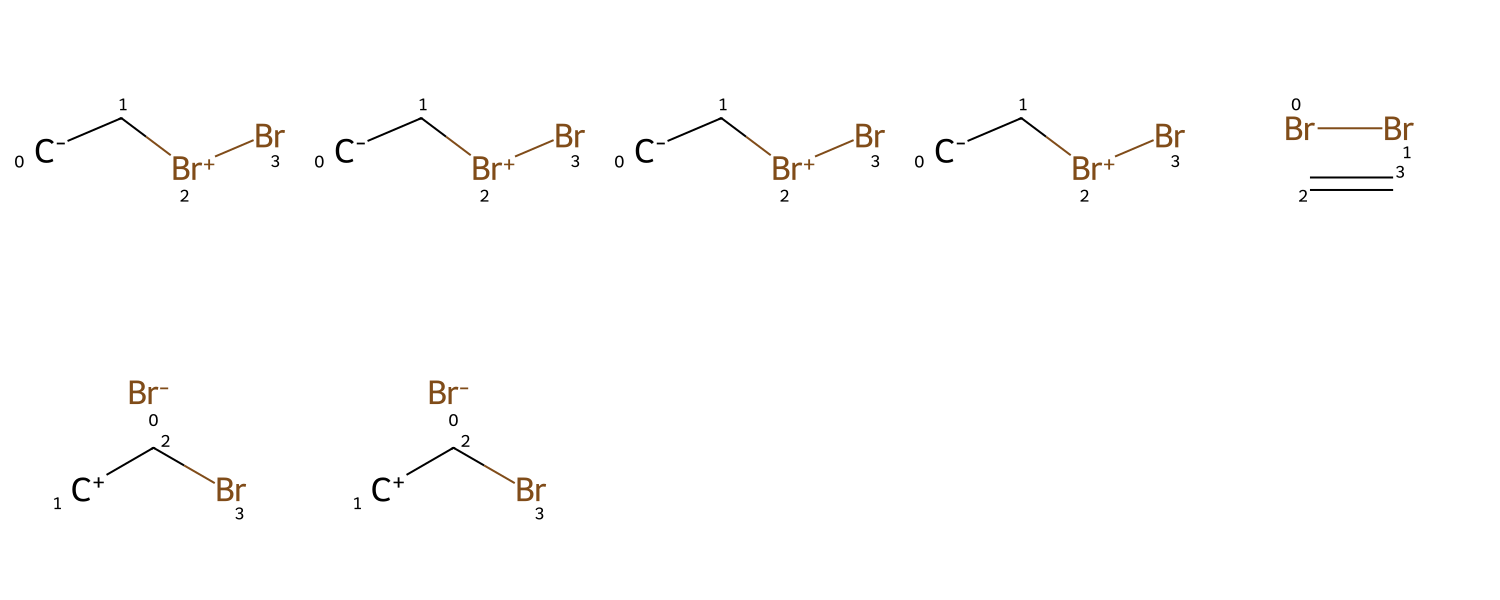

In [17]:
smiles_inp = 'C=C.BrBr'
connected_mols = execute_step(smiles_inp)
cleaner_mols = []
for mol in connected_mols:
    mola = Chem.MolToSmiles(mol)
    cleaner_mols.append(Chem.MolFromSmiles(mola))
Chem.Draw.MolsToGridImage(cleaner_mols, molsPerRow=5, subImgSize=(300, 300))


In [387]:
label = 0
for mol in connected_mols:
    label += 1
    print(str(label)+'. ' + Chem.MolToSmiles(mol))

1. CCCC.OC([CH-][P+](c1ccccc1)(c1ccccc1)c1ccccc1)c1ccccc1.[Li+]


In [277]:
def write_reaction_smiles(smiles, product):
    with open ("reactions.txt", 'a', encoding='utf-8') as file:
        line = smiles + ">>" + Chem.MolToSmiles(product)
        file.write(line +"\n")
    

In [278]:
write_reaction_smiles(smiles_inp, cleaner_mols[19])

In [269]:
Chem.MolToSmiles(connected_mols[0])

'C=CC.O=C([OH+][O-])c1ccccc1'

In [367]:
import unittest
class TestChemicalReactions(unittest.TestCase):
    def test_sn2_reaction(self):
        # SN2 reaction: CH3CH2Br + I- -> CH3CH2I + Br-
        reactant = "CCBr.[I-]"
        expected_products = {"CCI.[Br-]"}
        expected_products_inchi = {Chem.MolToInchi(Chem.MolFromSmiles(mol)) for mol in expected_products}
        products = execute_step(reactant)
        product_inchi = {Chem.MolToInchi(mol) for mol in products}
        self.assertTrue(expected_products_inchi.issubset(product_inchi))

    def test_hydroboration_step_1(self):
        # Hydroboration: BH3 + CH2=CH2 -> CH3CH2BH2
        reactant = "B.C=C"
        expected_products = {"[BH3-]C[CH2+]"}
        expected_products_inchi = {Chem.MolToInchi(Chem.MolFromSmiles(mol)) for mol in expected_products}
        products = execute_step(reactant)
        product_inchi = {Chem.MolToInchi(mol) for mol in products}
        self.assertTrue(expected_products_inchi.issubset(product_inchi))

    def test_hydroboration_step_2(self):
        # Hydroboration: BH3 + CH2=CH2 -> CH3CH2BH2
        reactant = "[BH3-]C[CH2+]"
        expected_products = {"BCC"}
        expected_products_inchi = {Chem.MolToInchi(Chem.MolFromSmiles(mol)) for mol in expected_products}
        products = execute_step(reactant)
        product_inchi = {Chem.MolToInchi(mol) for mol in products}
        self.assertTrue(expected_products_inchi.issubset(product_inchi))
    

    def test_cyanide_addition_to_carbonyl(self):
        # Cyanide addition: CH3C=O + CN- -> CH3C(OH)CN
        # both cyanide and isocyanide products
        reactant = "CC=O.[C-]#N"
        expected_products = {"CC([O-])C#N", "[C-]#[N+]C(C)[O-]"}
        expected_products_inchi = {Chem.MolToInchi(Chem.MolFromSmiles(mol)) for mol in expected_products}
        products = execute_step(reactant)
        product_inchi = {Chem.MolToInchi(mol) for mol in products}
        self.assertTrue(expected_products_inchi.issubset(product_inchi))

    def test_protonation_of_alkene(self):
        # Protonation: CH2=CH2 + H+ -> CH3CH2+
        reactant = "CC=C.[H+]"
        expected_products = {"[H]C([CH2+])C", "[H]C[CH+]C"}
        products = execute_step(reactant)
        expected_products_inchi = {Chem.MolToInchi(Chem.MolFromSmiles(mol)) for mol in expected_products}
        products = execute_step(reactant)
        product_inchi = {Chem.MolToInchi(mol) for mol in products}
        self.assertTrue(expected_products_inchi.issubset(product_inchi))

    def test_alpha_deprotonation_of_ketone(self):
        # Alpha deprotonation: CH3C(=O)CH3 + B- -> [CH2-]C(=O)CH3 + BH
        reactant = "CC(=O)C.[OH-]"
        expected_products = {"O.[CH2-]C(C)=O", "CC(C)([O-])O"}
        products = execute_step(reactant)
        expected_products_inchi = {Chem.MolToInchi(Chem.MolFromSmiles(mol)) for mol in expected_products}
        products = execute_step(reactant)
        product_inchi = {Chem.MolToInchi(mol) for mol in products}
        self.assertTrue(expected_products_inchi.issubset(product_inchi))


In [368]:
unittest.main(argv=[''], exit=False)

....RDKit WARNING: [16:33:45] WARNING: Proton(s) added/removed
RDKit WARNING: [16:33:45] WARNING: Proton(s) added/removed
RDKit WARNING: [16:33:45] WARNING: Proton(s) added/removed
RDKit WARNING: [16:33:45] WARNING: Omitted undefined stereo
RDKit WARNING: [16:33:45] WARNING: Omitted undefined stereo
RDKit WARNING: [16:33:45] WARNING: Proton(s) added/removed
RDKit WARNING: [16:33:45] WARNING: Charges were rearranged; Accepted unusual valence(s): O(4)
RDKit WARNING: [16:33:45] WARNING: Omitted undefined stereo
RDKit WARNING: [16:33:45] WARNING: Omitted undefined stereo
RDKit WARNING: [16:33:45] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [16:33:45] WARNING: not removing hydrogen atom without neighbors
..
----------------------------------------------------------------------
Ran 6 tests in 0.047s

OK
